# STAT GR5398 — Assignment 1: FinRL-Trading

**Submission candidate — Price-Covered Top 20.** Workflow: prepare fundamentals → machine-learning predictions across 11 sectors → define price-covered investable universe → equal-weight Top 20 portfolio → one-day signal lag → adjusted close-to-close backtest → SPY comparison.

**Run instructions:** Put this notebook alongside `prepared/`, `outputs/` and `ml_model.py` in `source_code/`. Existing training output is reused by default; the notebook does **not** retrain models unless explicitly enabled. Data and predictions are local, not embedded in the notebook.

**Research caveat:** This is an exploratory historical analysis, **not** a fully point-in-time or independently out-of-sample validated strategy.


## 1. Setup and inputs

Expected precomputed inputs: `prepared/final_ratios.csv`, `prepared/sector10.xlsx` … `sector60.xlsx`, `prepared/daily.csv`, and (after stock selection) `outputs/stock_selection/stock_selected.csv`.

**Efficiency:** preprocessing and model training are optional because they have already been run during experimentation. Their source functions remain below for reproducibility.

In [1]:
import os
import sys
import time
import warnings
from pathlib import Path
from datetime import datetime as dt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
DATA_DIR = Path("prepared")
SELECTION_DIR = Path("outputs/stock_selection")
BACKTEST_DIR = Path("outputs/backtest")
FIGURE_DIR = Path("outputs/figures")
for directory in (SELECTION_DIR, BACKTEST_DIR, FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print("Python:", sys.executable)
print("Working directory:", Path.cwd())

Python: /Users/bruceqi/miniforge3/envs/finrl/bin/python
Working directory: /Users/bruceqi/Downloads/STAT-GR5398-Columbia-University/Fall-2026/Assignment1/FinRL-Trading/source_code


## 2. Data preparation (original helper functions)

The original pre-processing implementation is retained below. It relies on WRDS/Compustat-derived fundamental and daily price data. Verify historical constituent eligibility, ticker–gvkey stability, and when financial reports became publicly available before treating resulting signals as bias-free.

In [2]:
def load_data(fundamental_file, price_file):
    """
    Load fundamental and price data from CSV files.
    
    Args:
        fundamental_file (str): Path to fundamental data CSV file
        price_file (str): Path to price data CSV file
        
    Returns:
        tuple: (fundamental_df, price_df)
    """
    print("Loading data files...")
    
    if not os.path.isfile(fundamental_file):
        raise FileNotFoundError(f"Fundamental file {fundamental_file} not found.")
    
    if not os.path.isfile(price_file):
        raise FileNotFoundError(f"Price file {price_file} not found.")
    
    # Load fundamental data
    fund_df = pd.read_csv(fundamental_file)
    print(fund_df.head())
    
    # For price data, only load necessary columns to save memory
    print("Loading price data (only necessary columns)...")
    price_columns = ['gvkey', 'tic', 'datadate', 'prccd', 'ajexdi']
    df_daily_price = pd.read_csv(price_file, usecols=price_columns)
    print(df_daily_price.head())
    
    print(f"Fundamental data shape: {fund_df.shape}")
    print(f"Price data shape: {df_daily_price.shape}")
    print(f"Unique tickers in fundamental data: {len(fund_df.tic.unique())}")
    print(f"Unique tickers in price data: {len(df_daily_price.tic.unique())}")
    
    return fund_df, df_daily_price

In [3]:
def adjust_trade_dates(fund_df):
    """
    Adjust trade dates to use trading dates instead of quarterly report dates.
    
    Args:
        fund_df (pandas.DataFrame): Fundamental data DataFrame
        
    Returns:
        pandas.DataFrame: DataFrame with adjusted trade dates
    """
    print("Adjusting trade dates...")
    
    # Convert datadate to datetime first, then to integer format
    datadate_dt = pd.to_datetime(fund_df['datadate'])

    fund_df['tradedate'] = ((datadate_dt.dt.to_period('Q')).dt.end_time.dt.normalize())
    fund_df['reportdate'] = fund_df["rdq"]
    
    return fund_df

In [4]:
def calculate_adjusted_close(fund_df):
    """
    Calculate adjusted close price.
    
    Args:
        fund_df (pandas.DataFrame): Fundamental data DataFrame
        
    Returns:
        pandas.DataFrame: DataFrame with adjusted close price
    """
    print("Calculating adjusted close price...")
    fund_df['adj_close_q'] = fund_df.prccq / fund_df.adjex
    return fund_df

In [5]:
def match_tickers_and_gvkey(fund_df, df_daily_price):
    """
    Match tickers and gvkey for fundamental and price data.
    
    Args:
        fund_df (pandas.DataFrame): Fundamental data DataFrame
        df_daily_price (pandas.DataFrame): Price data DataFrame
        
    Returns:
        pandas.DataFrame: Filtered fundamental data DataFrame
    """
    print("Matching tickers and gvkey...")
    
    # Create mapping from ticker to gvkey
    tic_to_gvkey = {}
    df_daily_groups = list(df_daily_price.groupby('tic'))
    
    for tic, df_ in df_daily_groups:
        tic_to_gvkey[tic] = df_.gvkey.iloc[0]
    
    print(f"Original fundamental data shape: {fund_df.shape}")
    
    # Filter fundamental data to only include tickers present in price data
    fund_df = fund_df[np.isin(fund_df.tic, list(tic_to_gvkey.keys()))]
    
    print(f"Filtered fundamental data shape: {fund_df.shape}")
    print(f"Unique gvkeys: {len(fund_df.gvkey.unique())}")
    
    # Add gvkey mapping
    fund_df['gvkey'] = [tic_to_gvkey[x] for x in fund_df['tic']]
    
    return fund_df

In [6]:
def calculate_next_quarter_returns(fund_df):
    """
    Calculate next quarter's return for each stock.
    
    Args:
        fund_df (pandas.DataFrame): Fundamental data DataFrame
        
    Returns:
        pandas.DataFrame: DataFrame with next quarter returns
    """
    print("Calculating next quarter returns...")
    
    fund_df['date'] = fund_df["tradedate"]
    # fund_df['date'] = pd.to_datetime(fund_df['date'], format="%Y-%m%d")
    fund_df['date'] = pd.to_datetime(fund_df['date'])
    fund_df.drop_duplicates(["date", "gvkey"], keep='last', inplace=True)
    
    # Calculate next quarter return for each stock
    l_df = list(fund_df.groupby('gvkey'))
    for tic, df in l_df:
        df.reset_index(inplace=True, drop=True)
        df = df.sort_values('date')
        # Calculate next quarter's return
        df['y_return'] = np.log(df['adj_close_q'].shift(-1) / df['adj_close_q'])
    
    fund_df = pd.concat([x[1] for x in l_df])
    
    print(f"Data shape after calculating returns: {fund_df.shape}")
    return fund_df

In [7]:
def calculate_basic_ratios(fund_df):
    """
    Calculate basic financial ratios (PE, PS, PB).
    
    Args:
        fund_df (pandas.DataFrame): Fundamental data DataFrame
        
    Returns:
        pandas.DataFrame: DataFrame with basic ratios
    """
    print("Calculating basic financial ratios...")
    
    fund_df['pe'] = fund_df.prccq / fund_df.epspxq
    fund_df['ps'] = fund_df.prccq / (fund_df.revtq / fund_df.cshoq)
    fund_df['pb'] = fund_df.prccq / ((fund_df.atq - fund_df.ltq) / fund_df.cshoq)
    
    return fund_df

In [8]:
def select_columns(fund_df):
    """
    Select relevant columns for analysis.
    
    Args:
        fund_df (pandas.DataFrame): Fundamental data DataFrame
        
    Returns:
        pandas.DataFrame: DataFrame with selected columns
    """
    print("Selecting relevant columns...")
    
    items = [
        'date', 'gvkey', 'tic', 'gsector',
        'oiadpq', 'revtq', 'niq', 'atq', 'teqq', 'epspiy', 'ceqq', 'cshoq', 'dvpspq',
        'actq', 'lctq', 'cheq', 'rectq', 'cogsq', 'invtq', 'apq', 'dlttq', 'dlcq', 'ltq',
        'pe', 'ps', 'pb', 'adj_close_q', 'y_return', 'reportdate'
    ]
    
    fund_data = fund_df[items]
    
    # Rename columns for readability
    fund_data = fund_data.rename(columns={
        'oiadpq': 'op_inc_q',
        'revtq': 'rev_q',
        'niq': 'net_inc_q',
        'atq': 'tot_assets',
        'teqq': 'sh_equity',
        'epspiy': 'eps_incl_ex',
        'ceqq': 'com_eq',
        'cshoq': 'sh_outstanding',
        'dvpspq': 'div_per_sh',
        'actq': 'cur_assets',
        'lctq': 'cur_liabilities',
        'cheq': 'cash_eq',
        'rectq': 'receivables',
        'cogsq': 'cogs_q',
        'invtq': 'inventories',
        'apq': 'payables',
        'dlttq': 'long_debt',
        'dlcq': 'short_debt',
        'ltq': 'tot_liabilities'
    })
    
    return fund_data

In [9]:
def calculate_financial_ratios(fund_data):
    """
    Calculate comprehensive financial ratios.
    
    Args:
        fund_data (pandas.DataFrame): Fundamental data DataFrame
        
    Returns:
        pandas.DataFrame: DataFrame with all financial ratios
    """
    print("Calculating comprehensive financial ratios...")
    
    # Set data type to series
    date = fund_data['date'].to_frame('date').reset_index(drop=True)
    reportdate = fund_data['reportdate'].to_frame('reportdate').reset_index(drop=True)
    tic = fund_data['tic'].to_frame('tic').reset_index(drop=True)
    gvkey = fund_data['gvkey'].to_frame('gvkey').reset_index(drop=True)
    adj_close_q = fund_data['adj_close_q'].to_frame('adj_close_q').reset_index(drop=True)
    y_return = fund_data['y_return'].to_frame('y_return').reset_index(drop=True)
    gsector = fund_data['gsector'].to_frame('gsector').reset_index(drop=True)
    pe = fund_data['pe'].to_frame('pe').reset_index(drop=True)
    ps = fund_data['ps'].to_frame('ps').reset_index(drop=True)
    pb = fund_data['pb'].to_frame('pb').reset_index(drop=True)
    
    # Profitability ratios
    print("  Calculating profitability ratios...")
    
    # Operating Margin
    OPM = pd.Series(np.empty(fund_data.shape[0], dtype=object), name='OPM')
    for i in range(0, fund_data.shape[0]):
        if i-3 < 0:
            OPM[i] = np.nan
        elif fund_data.iloc[i, 1] != fund_data.iloc[i-3, 1]:
            OPM.iloc[i] = np.nan
        else:
            OPM.iloc[i] = np.sum(fund_data['op_inc_q'].iloc[i-3:i]) / np.sum(fund_data['rev_q'].iloc[i-3:i])
    OPM = pd.Series(OPM).to_frame().reset_index(drop=True)
    
    # Net Profit Margin
    NPM = pd.Series(np.empty(fund_data.shape[0], dtype=object), name='NPM')
    for i in range(0, fund_data.shape[0]):
        if i-3 < 0:
            NPM[i] = np.nan
        elif fund_data.iloc[i, 1] != fund_data.iloc[i-3, 1]:
            NPM.iloc[i] = np.nan
        else:
            NPM.iloc[i] = np.sum(fund_data['net_inc_q'].iloc[i-3:i]) / np.sum(fund_data['rev_q'].iloc[i-3:i])
    NPM = pd.Series(NPM).to_frame().reset_index(drop=True)
    
    # Return On Assets
    ROA = pd.Series(np.empty(fund_data.shape[0], dtype=object), name='ROA')
    for i in range(0, fund_data.shape[0]):
        if i-3 < 0:
            ROA[i] = np.nan
        elif fund_data.iloc[i, 1] != fund_data.iloc[i-3, 1]:
            ROA.iloc[i] = np.nan
        else:
            ROA.iloc[i] = np.sum(fund_data['net_inc_q'].iloc[i-3:i]) / fund_data['tot_assets'].iloc[i]
    ROA = pd.Series(ROA).to_frame().reset_index(drop=True)
    
    # Return on Equity
    ROE = pd.Series(np.empty(fund_data.shape[0], dtype=object), name='ROE')
    for i in range(0, fund_data.shape[0]):
        if i-3 < 0:
            ROE[i] = np.nan
        elif fund_data.iloc[i, 1] != fund_data.iloc[i-3, 1]:
            ROE.iloc[i] = np.nan
        else:
            ROE.iloc[i] = np.sum(fund_data['net_inc_q'].iloc[i-3:i]) / fund_data['sh_equity'].iloc[i]
    ROE = pd.Series(ROE).to_frame().reset_index(drop=True)
    
    # Per share items
    EPS = fund_data['eps_incl_ex'].to_frame('EPS').reset_index(drop=True)
    BPS = (fund_data['com_eq'] / fund_data['sh_outstanding']).to_frame('BPS').reset_index(drop=True)
    DPS = fund_data['div_per_sh'].to_frame('DPS').reset_index(drop=True)
    
    # Liquidity ratios
    print("  Calculating liquidity ratios...")
    cur_ratio = (fund_data['cur_assets'] / fund_data['cur_liabilities']).to_frame('cur_ratio').reset_index(drop=True)
    quick_ratio = ((fund_data['cash_eq'] + fund_data['receivables']) / fund_data['cur_liabilities']).to_frame('quick_ratio').reset_index(drop=True)
    cash_ratio = (fund_data['cash_eq'] / fund_data['cur_liabilities']).to_frame('cash_ratio').reset_index(drop=True)
    
    # Efficiency ratios
    print("  Calculating efficiency ratios...")
    
    # Inventory turnover ratio
    inv_turnover = pd.Series(np.empty(fund_data.shape[0], dtype=object), name='inv_turnover')
    for i in range(0, fund_data.shape[0]):
        if i-3 < 0:
            inv_turnover[i] = np.nan
        elif fund_data.iloc[i, 1] != fund_data.iloc[i-3, 1]:
            inv_turnover.iloc[i] = np.nan
        else:
            inv_turnover.iloc[i] = np.sum(fund_data['cogs_q'].iloc[i-3:i]) / fund_data['inventories'].iloc[i]
    inv_turnover = pd.Series(inv_turnover).to_frame().reset_index(drop=True)
    
    # Receivables turnover ratio
    acc_rec_turnover = pd.Series(np.empty(fund_data.shape[0], dtype=object), name='acc_rec_turnover')
    for i in range(0, fund_data.shape[0]):
        if i-3 < 0:
            acc_rec_turnover[i] = np.nan
        elif fund_data.iloc[i, 1] != fund_data.iloc[i-3, 1]:
            acc_rec_turnover.iloc[i] = np.nan
        else:
            acc_rec_turnover.iloc[i] = np.sum(fund_data['rev_q'].iloc[i-3:i]) / fund_data['receivables'].iloc[i]
    acc_rec_turnover = pd.Series(acc_rec_turnover).to_frame().reset_index(drop=True)
    
    # Payable turnover ratio
    acc_pay_turnover = pd.Series(np.empty(fund_data.shape[0], dtype=object), name='acc_pay_turnover')
    for i in range(0, fund_data.shape[0]):
        if i-3 < 0:
            acc_pay_turnover[i] = np.nan
        elif fund_data.iloc[i, 1] != fund_data.iloc[i-3, 1]:
            acc_pay_turnover.iloc[i] = np.nan
        else:
            acc_pay_turnover.iloc[i] = np.sum(fund_data['cogs_q'].iloc[i-3:i]) / fund_data['payables'].iloc[i]
    acc_pay_turnover = pd.Series(acc_pay_turnover).to_frame().reset_index(drop=True)
    
    # Leverage ratios
    print("  Calculating leverage ratios...")
    debt_ratio = (fund_data['tot_liabilities'] / fund_data['tot_assets']).to_frame('debt_ratio').reset_index(drop=True)
    debt_to_equity = (fund_data['tot_liabilities'] / fund_data['sh_equity']).to_frame('debt_to_equity').reset_index(drop=True)
    
    # Create final ratios dataframe
    ratios = pd.concat([
        date, gvkey, tic, gsector, adj_close_q, y_return,
        OPM, NPM, ROA, ROE, EPS, BPS, DPS,
        cur_ratio, quick_ratio, cash_ratio, inv_turnover, acc_rec_turnover, acc_pay_turnover,
        debt_ratio, debt_to_equity, pe, ps, pb, reportdate
    ], axis=1).reset_index(drop=True)
    
    return ratios

In [10]:
def handle_missing_values(ratios):
    """
    Handle missing values and infinite values in the dataset.
    
    Args:
        ratios (pandas.DataFrame): DataFrame with financial ratios
        
    Returns:
        pandas.DataFrame: Cleaned DataFrame
    """
    print("Handling missing values...")
    
    # Replace NAs and infinite values with zero initially
    final_ratios = ratios.copy()
    final_ratios = final_ratios.fillna(0)
    final_ratios = final_ratios.replace(np.inf, 0)
    
    # Define financial features columns
    features_column_financial = [
        'OPM', 'NPM', 'ROA', 'ROE', 'EPS', 'BPS', 'DPS', 'cur_ratio',
        'quick_ratio', 'cash_ratio', 'inv_turnover', 'acc_rec_turnover',
        'acc_pay_turnover', 'debt_ratio', 'debt_to_equity', 'pe', 'ps', 'pb'
    ]
    
    # Remove rows with zero adjusted close price
    final_ratios = final_ratios.drop(list(final_ratios[final_ratios.adj_close_q == 0].index)).reset_index(drop=True)
    
    # Convert to numeric and handle invalid values
    final_ratios['y_return'] = pd.to_numeric(final_ratios['y_return'], errors='coerce')
    for col in features_column_financial:
        if col in final_ratios.columns:
            final_ratios[col] = pd.to_numeric(final_ratios[col], errors='coerce')
    
    final_ratios['y_return'].replace([np.nan, np.inf, -np.inf], np.nan, inplace=True)
    final_ratios[features_column_financial].replace([np.nan, np.inf, -np.inf], np.nan, inplace=True)
    
    # Remove columns with too many invalid values
    dropped_col = []
    for col in features_column_financial:
        if col in final_ratios.columns and np.any(~np.isfinite(final_ratios[col])):
            final_ratios.drop(columns=[col], axis=1, inplace=True)
            dropped_col.append(col)
    
    # Remove rows with any missing values
    final_ratios.dropna(axis=0, inplace=True)
    final_ratios = final_ratios[final_ratios["reportdate"].ne(0)]  
    final_ratios = final_ratios.reset_index(drop=True)
    
    print(f"Dropped columns: {dropped_col}")
    print(f"Final data shape: {final_ratios.shape}")
    
    return final_ratios

In [11]:
def save_results(final_ratios, output_dir="outputs", include_sector0=False):
    """
    Save the processed data to files.
    
    Args:
        final_ratios (pandas.DataFrame): Final processed data
        output_dir (str): Output directory
        include_sector0 (bool): Whether to include sector 0 in sector-specific files (default: False)
    """
    print("Saving results...")
    
    # Create output directory if it doesn't exist
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)
    
    # Format date column
    # final_ratios.date = final_ratios.date.apply(lambda x: x.strftime('%Y-%m-%d'))
    
    # Save main results
    main_output_file = os.path.join(output_dir, 'final_ratios.csv')
    final_ratios.to_csv(main_output_file, index=False)
    print(f"Main results saved to: {main_output_file}")
    
    # Save by sector
    print("Saving sector-specific files...")
    sector_count = 0
    for sec, df_ in list(final_ratios.groupby('gsector')):
        # Skip sector 0 unless explicitly included
        if sec == 0 and not include_sector0:
            print(f"  Skipping Sector 0: {len(df_)} records (stocks with missing sector information)")
            continue
        
        sector_file = os.path.join(output_dir, f"sector{int(sec)}.xlsx")
        df_.to_excel(sector_file, index=False)
        print(f"  Sector {int(sec)}: {sector_file} ({len(df_)} records)")
        sector_count += 1
    
    print(f"  Total sectors saved: {sector_count}")
    
    return main_output_file

### Optional: reproduce data preparation

For the current run, use the **already generated** files under `prepared/`. The original preprocessing runner is preserved as a reference; it requires correct raw input paths and may not be equivalent to the separate `prepare_data.py` run used to generate the current prepared files.

In [12]:
RUN_PREPROCESSING = False

if RUN_PREPROCESSING:
    raise RuntimeError(
        "Use the documented prepare_data.py command with verified raw inputs; "
        "the original notebook's preprocessing paths were blank."
    )
else:
    required = [DATA_DIR / "final_ratios.csv", DATA_DIR / "daily.csv"]
    missing = [str(p) for p in required if not p.exists()]
    print("Prepared inputs ready" if not missing else f"Missing input files: {missing}")

Prepared inputs ready


## 3. Machine-learning stock selection

Models: Random Forest, LightGBM and XGBoost; predictions are combined across 11 sectors (10–60 in increments of 5). The supplied selection runner retains its original top-quartile selection rule. The exact hyperparameter grids are defined in `ml_model.py`, not in this notebook. Please submit that module as well.

In [13]:
import pandas as pd
from pathlib import Path

def create_directory_if_not_exists(directory_path):
    """
    Create directory if it doesn't exist
    
    Args:
        directory_path (str): Directory path
    """
    path = Path(directory_path)
    if not path.exists():
        path.mkdir(parents=True, exist_ok=True)
        print(f"✓ Created directory: {directory_path}")
    else:
        print(f"✓ Directory already exists: {directory_path}")

def quarter_ffill(df: pd.DataFrame) -> pd.DataFrame:
    qkey = df.index.to_period("Q")
    df = df.groupby(qkey).ffill()
    return df

def quarter_reportday_ffill(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df.index = pd.to_datetime(df.index)

    full_idx = pd.bdate_range(df.index.min(), df.index.max())

    out = df.reindex(full_idx)
    out = out.sort_index().copy()
    idx = out.index
    for col in out.columns:
        s = out[col]
        if not s.notna().any():
            continue
        dates = s.dropna().index
        for i, t0 in enumerate(dates):
            val = s.at[t0]
            t1 = dates[i + 1] if i + 1 < len(dates) else None
            cap = (t0.to_period('Q') + 1).end_time.normalize()
            mask = (idx > t0) & (idx < (t1 if t1 and t1 <= cap else cap + pd.Timedelta('1ns')))
            out.loc[mask, col] = val
    return out

In [14]:
def run_stock_selection(data_path, output_path):
    """
    Run stock selection model
    
    Args:
        data_path (str): Input sector files directory
        output_path (str): Output directory
    """
   # Define sector range
    sectors = range(10, 65, 5)
    
    # Set data directory path
    DATA_DIR = data_path
    FUNDAMENTAL_FILE = os.path.join(DATA_DIR, "final_ratios.csv")
    
    print(f"Using data directory: {DATA_DIR}")
    print(f"Fundamental data file: {FUNDAMENTAL_FILE}")
    print(f"Output directory: {output_path}")
    print(f"Sector range: {list(sectors)}")
    
    # Check if input file exists
    if not os.path.exists(FUNDAMENTAL_FILE):
        print(f"Error: Fundamental data file does not exist: {FUNDAMENTAL_FILE}")
        sys.exit(1)
    
    # Create output directory
    create_directory_if_not_exists(output_path)
    
    # gvkey is unique identifier
    df_dict = {'tic': [], 'predicted_return': [], 'trade_date': []}
    
    # ===== Run stock selection for all sectors in my_outputs directory =====
    start = time.time()
    print("\nStarting stock selection model for all sectors...")

    df_all = pd.DataFrame()
    
    for sector in sectors:
        sector_file = os.path.join(DATA_DIR, f"sector{sector}.xlsx")
        print(f"\nProcessing sector{sector}...")
        
        # Check if sector file exists
        if not os.path.exists(sector_file):
            print(f"   Warning: Sector file does not exist, skipping: {sector_file}")
            continue
        
        # Run model training - using files from specified directory
        cmd = f"{sys.executable} fundamental_run_model.py -sector_name sector{sector} -tic_column tic -fundamental {FUNDAMENTAL_FILE} -sector {sector_file}"
        print(f"Executing command: {cmd}")
        
        result = os.system(cmd)
        if result != 0:
            print(f" sector{sector} model training failed")
            continue
        
        # Read prediction results
        result_file = f"results/sector{sector}/df_predict_best.csv"
        if not os.path.exists(result_file):
            print(f" Prediction result file does not exist: {result_file}")
            continue

        df = pd.read_csv(result_file, index_col=0)
        df.index = pd.to_datetime(df.index)
        print(f"  Reading prediction results: {df.shape[0]} dates, {df.shape[1]} stocks")
        df = quarter_reportday_ffill(df)
        df_all = pd.concat([df_all, df], axis=1)
        print(f" sector{sector} processing completed")

    for idx in df_all.index:
        predicted_return = df_all.loc[idx]
        ### Choose top 25% stocks, or you can adjust by yourself
        btm_q = predicted_return.quantile(0.75)
        # top_q = predicted_return.quantile(1)
        predicted_return = predicted_return[predicted_return >= btm_q]
        # predicted_return = predicted_return[(predicted_return >= btm_q) & (predicted_return <= top_q)]
        for tic in predicted_return.index:
            df_dict["tic"].append(tic)
            df_dict["predicted_return"].append(predicted_return[tic])
            df_dict["trade_date"].append(idx)
    
    end = time.time()
    
    print(f"\nTotal time: {(end-start)/60:.2f} minutes")
    print(f"Processing completed! Total records: {len(df_dict['tic'])}")
    
    # Create result DataFrame
    df_result = pd.DataFrame(df_dict)
    
    # Save results to CSV file
    output_file = os.path.join(output_path, "stock_selected.csv")
    df_result.to_csv(output_file, index=False)
    print(f"Results saved to: {output_file}")
    
    # Display result statistics
    if len(df_result) > 0:
        print(f"\nResult statistics:")
        print(f"  Total records: {len(df_result)}")
        print(f"  Unique stocks: {df_result['tic'].nunique()}")
        print(f"  Date range: {df_result['trade_date'].min()} to {df_result['trade_date'].max()}")
        print(f"  Predicted return range: {df_result['predicted_return'].min():.4f} to {df_result['predicted_return'].max():.4f}")
    else:
        print("\nWarning: No stock selection results generated")

In [15]:
data_path = str(DATA_DIR)
output_path_step2 = str(SELECTION_DIR)
RUN_STOCK_SELECTION = False  # Set True only to deliberately re-train all 11 sectors

if RUN_STOCK_SELECTION:
    run_stock_selection(data_path, output_path_step2)
else:
    selection_file = SELECTION_DIR / "stock_selected.csv"
    print("Using saved predictions:", selection_file)
    print("File exists:", selection_file.exists())

Using saved predictions: outputs/stock_selection/stock_selected.csv
File exists: True


### Selection output diagnostics (one concise summary)

In [16]:
selection_file = SELECTION_DIR / "stock_selected.csv"
if not selection_file.exists():
    raise FileNotFoundError(f"Missing {selection_file}. Run stock selection once or restore its saved CSV.")
selected_stocks_df = pd.read_csv(selection_file, parse_dates=["trade_date"])
selected_stocks_df = selected_stocks_df.dropna(subset=["trade_date", "tic"])
selected_stocks_df = selected_stocks_df.drop_duplicates(subset=["trade_date", "tic"])
print("Selection records:", len(selected_stocks_df))
print("Unique tickers:", selected_stocks_df["tic"].nunique())
print("Signal range:", selected_stocks_df["trade_date"].min(), "to", selected_stocks_df["trade_date"].max())

Selection records: 171013
Unique tickers: 480
Signal range: 2020-05-01 00:00:00 to 2025-11-25 00:00:00


## 4. Portfolio construction — price-covered Top 20

The original selected-stock file contains securities without price columns in `prepared/daily.csv` (67 tickers across the full candidate universe). We **do not** zero-impute missing entire securities or silently discard their weights after selection. Instead, we explicitly redefine the eligible universe as stocks represented in the provided price panel and select the top 20 predicted returns **within that restricted universe**. This changes the original strategy definition and introduces selection/coverage limitations; it does not recover missing historical delisting returns.


In [17]:
# Retain a record of the original equal-weight selection universe for research context.
portfolio_weights_df = pd.crosstab(
    selected_stocks_df["trade_date"], selected_stocks_df["tic"]
).astype(float)
portfolio_weights_df = portfolio_weights_df.div(portfolio_weights_df.sum(axis=1), axis=0).sort_index()
portfolio_weights_df.index.name = "date"
print("Original selection weights:", portfolio_weights_df.shape)
print("This is a diagnostic, not the tradable price-covered portfolio.")


Original selection weights: (1453, 480)
This is a diagnostic, not the tradable price-covered portfolio.


## 5. Close-to-close backtest — restricted-universe Top 20

Prices from `prepared/daily.csv` are adjusted by `prccd/ajexdi` as in the original backtest. Predictive ranks are formed on each available signal date, then shifted by **one row of common trading dates** for implementation. Transaction costs use 10 bps times the *absolute target-weight-change* measure; this is a simplified turnover convention, not an execution simulator. Missing returns of **active** positions cause the calculation to stop rather than being silently treated as zero.


In [18]:
# Read existing stock prices once; do not retrain or download anything.
price_data = pd.read_csv(
    DATA_DIR / "daily.csv",
    usecols=["tic", "datadate", "prccd", "ajexdi"],
    parse_dates=["datadate"]
)
price_data["close_adj"] = price_data["prccd"] / price_data["ajexdi"].replace(0, np.nan)
prices = price_data.pivot_table(
    index="datadate", columns="tic", values="close_adj", aggfunc="last"
).sort_index()
stock_returns = prices.pct_change(fill_method=None)

# Explicitly define the covered universe *before* ranking predictions.
covered_tickers = set(prices.columns)
original_tickers = set(selected_stocks_df["tic"])
missing_entire_tickers = sorted(original_tickers - covered_tickers)
print("Original predicted tickers:", len(original_tickers))
print("Tickers without a price column:", len(missing_entire_tickers))
print("Restricted-universe rule: rank predictions only within covered tickers")

ranked = (selected_stocks_df
    .dropna(subset=["predicted_return", "trade_date", "tic"])
    .loc[lambda x: x["tic"].isin(covered_tickers)]
    .sort_values(["trade_date", "predicted_return", "tic"], ascending=[True, False, True])
    .drop_duplicates(["trade_date", "tic"])
    .groupby("trade_date", sort=False).head(20).copy())
ranked["weight"] = 1.0 / ranked.groupby("trade_date")["tic"].transform("size")
signal_weights = ranked.pivot(index="trade_date", columns="tic", values="weight").fillna(0.0).sort_index()

spy_prices = pd.read_csv(
    BACKTEST_DIR / "spy_prices.csv", index_col=0, parse_dates=True
).sort_index()
spy_returns = pd.to_numeric(spy_prices["Close"], errors="coerce").pct_change(fill_method=None)

evaluation_dates = signal_weights.index.intersection(stock_returns.index).intersection(spy_prices.index).sort_values()
assert len(evaluation_dates) > 100, "Insufficient common dates"
signal_weights = signal_weights.reindex(
    index=evaluation_dates, columns=stock_returns.columns, fill_value=0.0
).fillna(0.0)
held_weights = signal_weights.shift(1).fillna(0.0)
aligned_returns = stock_returns.reindex(index=evaluation_dates, columns=held_weights.columns)
missing_exposure = held_weights.where(aligned_returns.isna(), 0.0).sum(axis=1)
print("Evaluation period:", evaluation_dates.min().date(), "to", evaluation_dates.max().date())
print("Missing held-return days:", int((missing_exposure > 1e-12).sum()))
print("Maximum missing held weight:", float(missing_exposure.max()))
if (missing_exposure > 1e-12).any():
    raise ValueError("Active holdings have missing stock returns. Stop and resolve before interpreting performance.")


Original predicted tickers: 480
Tickers without a price column: 67
Restricted-universe rule: rank predictions only within covered tickers
Evaluation period: 2020-05-01 to 2025-09-30
Missing held-return days: 0
Maximum missing held weight: 0.0


In [19]:
FEE_RATE = 0.001
gross_returns = (held_weights * aligned_returns.fillna(0.0)).sum(axis=1)
turnover = held_weights.diff().abs().sum(axis=1)
turnover.iloc[0] = 0.0  # match original simplified backtest convention
net_returns = gross_returns - FEE_RATE * turnover

price_covered_result = pd.DataFrame({
    "net_ret": net_returns,
    "turnover": turnover,
    "nav": (1 + net_returns).cumprod()
}, index=evaluation_dates)

comparison_returns = pd.DataFrame({
    "Price-Covered Top 20": net_returns,
    "SPY": spy_returns.reindex(evaluation_dates),
}).dropna()

def performance_metrics(r):
    nav = (1 + r).cumprod()
    vol = r.std()
    return pd.Series({
        "Cumulative Return (%)": (nav.iloc[-1] - 1) * 100,
        "Annualized Return (%)": (nav.iloc[-1] ** (252 / len(r)) - 1) * 100,
        "Annualized Volatility (%)": vol * np.sqrt(252) * 100,
        "Sharpe (rf=0)": r.mean() / vol * np.sqrt(252) if vol > 0 else np.nan,
        "Max Drawdown (%)": (nav / nav.cummax() - 1).min() * 100,
    })

performance_table = comparison_returns.apply(performance_metrics).T
comparison_nav = (1 + comparison_returns).cumprod()
print("\nFINAL COMPARISON (computed, not hard-coded):")
print(performance_table.round(2).to_string())
print("\nAverage daily turnover:", round(float(turnover.mean()), 4))

# Write to distinct filenames; never overwrite historical Top-K experimental outputs.
price_covered_result.to_csv(BACKTEST_DIR / "price_covered_top20.csv")
performance_table.to_csv(BACKTEST_DIR / "price_covered_top20_vs_spy.csv")
comparison_returns.to_csv(BACKTEST_DIR / "price_covered_final_daily_returns.csv")
comparison_nav.to_csv(BACKTEST_DIR / "price_covered_final_nav.csv")



FINAL COMPARISON (computed, not hard-coded):
                      Cumulative Return (%)  Annualized Return (%)  Annualized Volatility (%)  Sharpe (rf=0)  Max Drawdown (%)
Price-Covered Top 20                 194.76                  22.16                      24.74           0.93            -38.95
SPY                                  148.07                  18.32                      17.55           1.05            -24.50

Average daily turnover: 0.0455


## 6. Benchmark comparison and report figures

Both curves use adjusted close-to-close returns aligned to the same trading days. SPY prices come from the previously saved, dividend-adjusted Yahoo Finance CSV; this Notebook does not require network access. The strategy does **not** invest before its first lagged signal, while the SPY benchmark is invested from the beginning of the aligned sample.


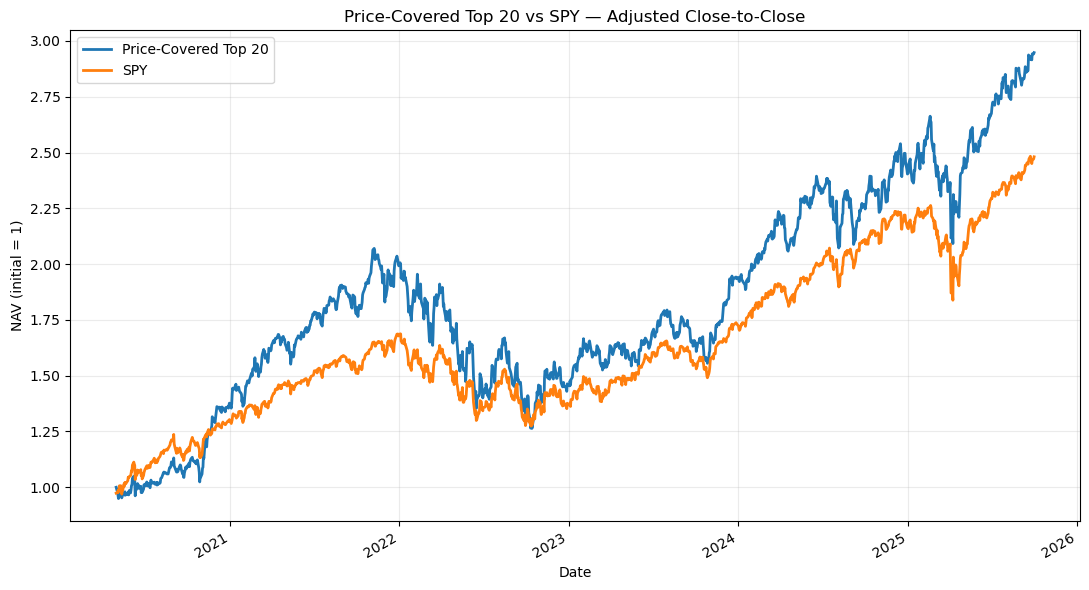

Calendar year / partial-year returns (%):
      Price-Covered Top 20    SPY  Excess Return (pp)
2020                 37.70  30.35                7.35
2021                 44.69  28.73               15.96
2022                -26.81 -18.18               -8.63
2023                 32.65  26.18                6.48
2024                 24.26  24.89               -0.62
2025                 22.63  14.66                7.97


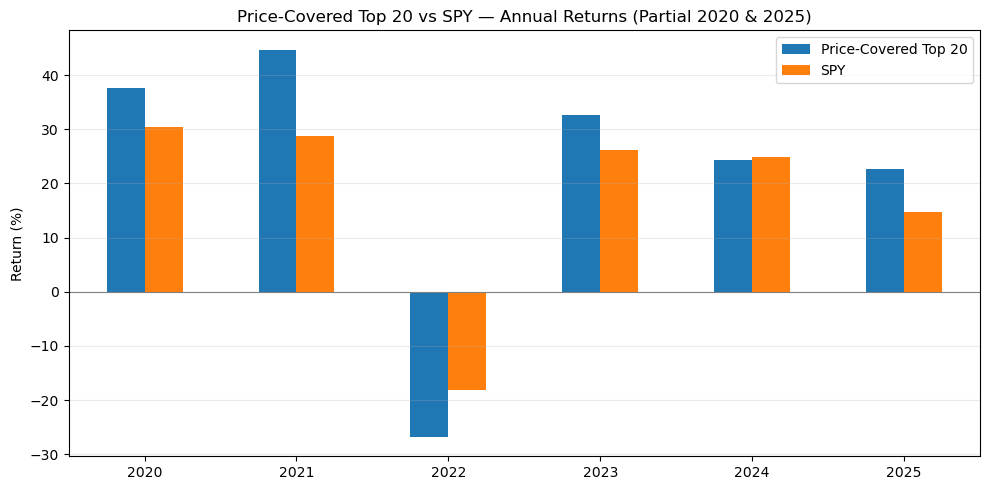

In [20]:
ax = comparison_nav[["Price-Covered Top 20", "SPY"]].plot(figsize=(11, 6), linewidth=2)
ax.set(title="Price-Covered Top 20 vs SPY — Adjusted Close-to-Close", xlabel="Date", ylabel="NAV (initial = 1)")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "price_covered_top20_vs_spy_nav.png", dpi=200)
plt.show()

annual = (1 + comparison_returns).groupby(comparison_returns.index.year).prod().sub(1).mul(100)
annual["Excess Return (pp)"] = annual["Price-Covered Top 20"] - annual["SPY"]
print("Calendar year / partial-year returns (%):")
print(annual.round(2).to_string())
annual.to_csv(BACKTEST_DIR / "price_covered_annual_returns.csv")

ax = annual[["Price-Covered Top 20", "SPY"]].plot(kind="bar", figsize=(10, 5), rot=0)
ax.set(title="Price-Covered Top 20 vs SPY — Annual Returns (Partial 2020 & 2025)", ylabel="Return (%)")
ax.axhline(0, color="gray", linewidth=0.8)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "price_covered_annual_vs_spy.png", dpi=200)
plt.show()


## 7. Research interpretation and limitations

**Previously observed local benchmark (2020-05-01 to 2025-09-30; rerun tables above are authoritative):** The Price-Covered Top 20 produced **+194.76% cumulative return**, **22.16% annualized return**, **0.93 Sharpe (rf=0)**, and **−38.95% maximum drawdown**. SPY produced **+148.07% cumulative return**, **18.32% annualized return**, **1.05 Sharpe**, and **−24.50% maximum drawdown**. Thus the candidate portfolio outperformed in raw cumulative return but underperformed in risk-adjusted return and experienced deeper drawdowns. Figures in this paragraph are prior local observations, not a substitute for the computed table.

**Material qualifications:**

- **Restricted price coverage:** 67 predicted tickers had no corresponding columns in the supplied `prepared/daily.csv`. The final strategy selects only among price-covered tickers. This is **not** a recovery of the original Top 20 and may bias the investable universe toward covered/surviving stocks. The original unrestricted Top 20's +184.06% exploratory result used unpriced holdings and must **not** be presented as fully valid.
- **Look-ahead risk:** Signal weights are shifted one trading day, but `final_ratios.csv` has `date` and `reportdate` values whose interpretation and availability were not fully validated (some reported dates precede quarter-end). A lagged trade is **not** proof that the ML features were public at signal creation.
- **In-sample choice:** Top 20 and the covered universe were chosen after inspecting the same historical period; this is not independent out-of-sample evidence.
- **Transaction costs and execution:** A 10-bp fee multiplied by the sum of absolute changes in target weights is a simplified approximation; no drift-aware execution model, bid–ask spread, market impact or complete initial-entry charge.
- **Survivorship/delistings:** Full historical membership and delisting cashflows have not been audited. Price coverage filtering cannot establish freedom from survivorship bias.
- **Data and replication:** This notebook requires external local datasets and predictions already prepared in `source_code/`. The model-retraining switch remains off by default.

**Conclusion:** The candidate has encouraging **exploratory** cumulative performance but substantially higher drawdown than SPY. Point-in-time feature engineering, coverage reconstruction and genuine walk-forward evaluation are prerequisites for credible investment claims.


In [21]:
print("Submission outputs:")
for path in [
    BACKTEST_DIR / "price_covered_top20.csv",
    BACKTEST_DIR / "price_covered_top20_vs_spy.csv",
    BACKTEST_DIR / "price_covered_annual_returns.csv",
    FIGURE_DIR / "price_covered_top20_vs_spy_nav.png",
    FIGURE_DIR / "price_covered_annual_vs_spy.png",
]:
    print(path, "OK" if path.exists() else "MISSING")


Submission outputs:
outputs/backtest/price_covered_top20.csv OK
outputs/backtest/price_covered_top20_vs_spy.csv OK
outputs/backtest/price_covered_annual_returns.csv OK
outputs/figures/price_covered_top20_vs_spy_nav.png OK
outputs/figures/price_covered_annual_vs_spy.png OK
